Import Necessary Libraries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
import gensim.downloader as api
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

GPU availability or not

In [27]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Using device: {device}")

Using device: cuda


Loading and Preprocessing the Dataset

In [28]:
file_path = '/content/IMDB Dataset.csv'
imdb_data = pd.read_csv(file_path)
imdb_data['sentiment'] = imdb_data['sentiment'].map({'positive': 1, 'negative': 0})
texts, labels = imdb_data['review'], imdb_data['sentiment']

Splitting the dataset


In [29]:
X_train, X_temp, y_train, y_temp = train_test_split(texts, labels, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Preprocess and calculate average length
avg_length = int(np.mean([len(re.sub(r'[^a-zA-Z]', ' ', text.lower()).split()) for text in X_train]))


Creating Voc using CountVectorizer

In [30]:
# Create vocabulary using CountVectorizer
vectorizer = CountVectorizer(max_features=10000)
vectorizer.fit(X_train)
custom_vocab = vectorizer.vocabulary_

# Load pretrained Word2Vec embeddings
word2vec = api.load('word2vec-google-news-300')
embedding_dim = 300
average_embedding = np.mean(word2vec.vectors, axis=0)
vocab = {'PAD': 0, 'UNK': 1}
vocab.update({word: idx + 2 for idx, word in enumerate(custom_vocab)})
embedding_matrix = np.zeros((len(vocab), embedding_dim))
embedding_matrix[0] = np.zeros(embedding_dim)  # PAD token
embedding_matrix[1] = average_embedding  # UNK token
for word, idx in vocab.items():
    if word in word2vec:
        embedding_matrix[idx] = word2vec[word]
    elif idx > 1:
        embedding_matrix[idx] = average_embedding

[==================================================] 100.0% 1662.8/1662.8MB downloaded


Creating IMDB Dataset

In [31]:
class IMDBDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_length):
        self.texts = [self.tokenize(text, vocab, max_length) for text in texts]
        self.labels = labels

    def tokenize(self, text, vocab, max_length):
        text = re.sub(r'[^a-zA-Z]', ' ', text.lower()).split()
        tokens = [vocab.get(word, vocab['UNK']) for word in text]
        return tokens + [vocab['PAD']] * (max_length - len(tokens)) if len(tokens) < max_length else tokens[:max_length]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.texts[idx]), torch.tensor(self.labels.iloc[idx])

train_dataset = IMDBDataset(X_train, y_train, vocab, avg_length)
val_dataset = IMDBDataset(X_val, y_val, vocab, avg_length)
test_dataset = IMDBDataset(X_test, y_test, vocab, avg_length)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

Defining Stacked Bidirectional RNN Model

In [52]:
class StackedBiRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, pretrained_embeddings, rnn_type='LSTM', use_pooling=True,dropout=0.5):
        super(StackedBiRNN, self).__init__()
        self.use_pooling = use_pooling
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(pretrained_embeddings, dtype=torch.float32), freeze=False)
        rnn_class = nn.LSTM if rnn_type == 'LSTM' else nn.GRU
        self.rnn = rnn_class(embed_dim, hidden_dim, num_layers=num_layers, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2, 1)  # Bidirectional output size is doubled
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        embedded = self.embedding(x)
        rnn_out, _ = self.rnn(embedded)
        if self.use_pooling:
            pooled = torch.max(rnn_out, dim=1)[0]
            return self.sigmoid(self.fc(pooled)).squeeze()
        else:
            return self.sigmoid(self.fc(rnn_out[:, -1, :])).squeeze()

#Training phase
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for texts, labels in train_loader:
            texts, labels = texts.to(device), labels.float().to(device)
            optimizer.zero_grad()
            outputs = model(texts)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_losses.append(train_loss / len(train_loader))

        val_loss = 0
        model.eval()
        with torch.no_grad():
            for texts, labels in val_loader:
                texts, labels = texts.to(device), labels.float().to(device)
                outputs = model(texts)
                val_loss += criterion(outputs, labels).item()
        val_losses.append(val_loss / len(val_loader))

        print(f'Epoch {epoch+1}/{epochs}, Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}')

    return train_losses, val_losses

# Evaluation phase
from sklearn.metrics import precision_recall_fscore_support,classification_report

def detailed_evaluation(model, test_loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for texts, labels in test_loader:
            texts = texts.to(device)
            preds = (model(texts).squeeze() > 0.5).cpu().numpy()
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds)

    # Micro-average metrics
    precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(
        y_true, y_pred, average='micro'
    )

    # Macro-average metrics
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro'
    )

    # Detailed classification report
    report = classification_report(
        y_true, y_pred, target_names=['Class 0', 'Class 1'], digits=4, output_dict=True
    )

    return report, precision_micro, recall_micro, f1_micro, precision_macro, recall_macro, f1_macro




Initializing model, optimizer, and criterion

In [82]:
model = StackedBiRNN(len(vocab), embedding_dim, hidden_dim=16, num_layers=1,
                     pretrained_embeddings=embedding_matrix, rnn_type='LSTM',dropout=0.9).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001,weight_decay=1e-3)

In [83]:
train_losses, val_losses = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10)


Epoch 1/10, Train Loss: 0.6870, Val Loss: 0.6755
Epoch 2/10, Train Loss: 0.6283, Val Loss: 0.5656
Epoch 3/10, Train Loss: 0.5204, Val Loss: 0.4877
Epoch 4/10, Train Loss: 0.4157, Val Loss: 0.3695
Epoch 5/10, Train Loss: 0.3617, Val Loss: 0.3498
Epoch 6/10, Train Loss: 0.3316, Val Loss: 0.3392
Epoch 7/10, Train Loss: 0.3048, Val Loss: 0.3270
Epoch 8/10, Train Loss: 0.2906, Val Loss: 0.3196
Epoch 9/10, Train Loss: 0.2725, Val Loss: 0.3135
Epoch 10/10, Train Loss: 0.2594, Val Loss: 0.3170


Visualized losses

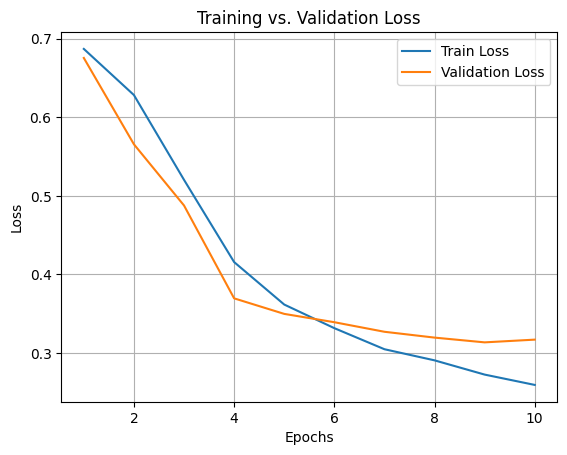

In [84]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs. Validation Loss')
plt.legend()
plt.grid()
plt.show()


Evaluating the Model on Test data


In [85]:
report, precision_micro, recall_micro, f1_micro, precision_macro, recall_macro, f1_macro = detailed_evaluation(model, test_loader)

print("Classification Metrics:")
for class_label, metrics in report.items():
    if class_label in ['Class 0', 'Class 1']:
        print(f"{class_label}: Precision={metrics['precision']:.4f}, Recall={metrics['recall']:.4f}, F1={metrics['f1-score']:.4f}")

print(f"Micro-Averaged Metrics: Precision={precision_micro:.4f}, Recall={recall_micro:.4f}, F1={f1_micro:.4f}")
print(f"Macro-Averaged Metrics: Precision={precision_macro:.4f}, Recall={recall_macro:.4f}, F1={f1_macro:.4f}")


Classification Metrics:
Class 0: Precision=0.8964, Recall=0.8530, F1=0.8742
Class 1: Precision=0.8618, Recall=0.9029, F1=0.8819
Micro-Averaged Metrics: Precision=0.8781, Recall=0.8781, F1=0.8781
Macro-Averaged Metrics: Precision=0.8791, Recall=0.8779, F1=0.8780
